# 03 · Client Age: Are the primary clients younger or older?

**Author:** Yurii  
**Question:** What is the age profile of the clients who used the online process?

**Data:** the 3 cleaned CSV files from `01_data_cleaning.ipynb` (experiment clients only).


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
clients_demo = pd.read_csv("cleaned_clients_demographics.csv")
clients_var = pd.read_csv("cleaned_clients_variation.csv")
web_events = pd.read_csv("cleaned_web_events.csv")

In [6]:
clients_demo.columns

Index(['client_id', 'clnt_tenure_yr', 'clnt_tenure_mnth', 'clnt_age', 'gendr',
       'num_accts', 'bal', 'calls_6_mnth', 'logons_6_mnth'],
      dtype='str')

In [7]:
clients_var.columns

Index(['client_id', 'Variation'], dtype='str')

In [8]:
web_events.columns

Index(['client_id', 'visitor_id', 'visit_id', 'process_step', 'date_time'], dtype='str')

In [9]:
clients_demo.head(10)

,client_id,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,gendr,num_accts,bal,calls_6_mnth,logons_6_mnth
0,836976,6.0,73.0,60.5,U,2.0,45105.30,6.0,9.0
1,2304905,7.0,94.0,58.0,U,2.0,110860.30,6.0,9.0
2,1439522,5.0,64.0,32.0,U,2.0,52467.79,6.0,9.0
3,1562045,16.0,198.0,49.0,M,2.0,67454.65,3.0,6.0
4,5126305,12.0,145.0,33.0,F,2.0,103671.75,0.0,3.0
5,3727881,5.0,71.0,30.5,U,2.0,23915.60,0.0,3.0
6,272934,5.0,66.0,58.5,U,2.0,27021.42,2.0,5.0
7,388801,30.0,361.0,57.5,M,5.0,522498.72,1.0,4.0
8,285619,30.0,369.0,67.5,M,2.0,299388.72,3.0,6.0
9,8198645,15.0,189.0,54.5,F,2.0,382303.83,6.0,9.0


In [10]:
# Select all clients who used the online process
online_clients = clients_demo[
    clients_demo['client_id'].isin(web_events['client_id'])
].drop_duplicates(subset='client_id')

# Analyze their age
online_clients['clnt_age'].describe().round(1)

count    50488.0
mean        47.3
std         15.5
min         17.0
25%         33.5
50%         48.0
75%         59.5
max         96.0
Name: clnt_age, dtype: float64

In [11]:
# Create age groups
online_clients['age_group'] = pd.cut(
    online_clients['clnt_age'],
    bins=[0, 35, 50, 65, float('inf')],
    labels=['Under 35', '35-49', '50-64', '65+'],
    right=False
)

# Calculate percentage of clients in each group
age_distribution = (
    online_clients['age_group']
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(1)
)

print(age_distribution)

age_group
Under 35    27.5
35-49       25.7
50-64       32.1
65+         14.7
Name: proportion, dtype: float64


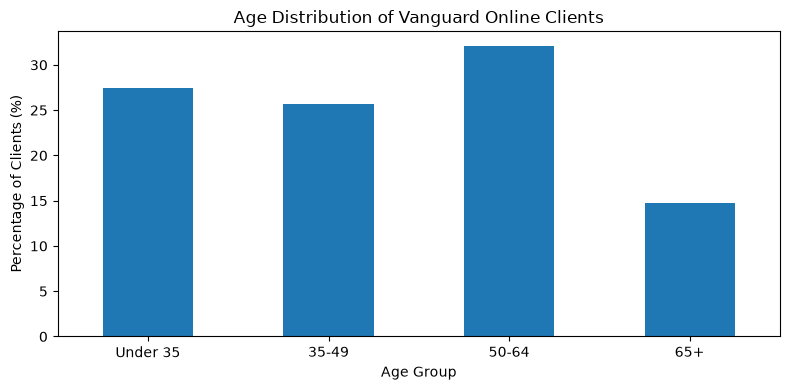

In [12]:
import matplotlib.pyplot as plt

age_distribution.plot(kind='bar', figsize=(8, 4))

plt.title('Age Distribution of Vanguard Online Clients')
plt.xlabel('Age Group')
plt.ylabel('Percentage of Clients (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

##### Vanguard's online clients are predominantly middle-aged, with 57.8% aged 35–64 and an average age of 47.3 (median 48). The largest segment is 50–64 (32.1%). This suggests that the digital experience should prioritize intuitive navigation and clear instructions across age groups.